# Biblical Typology — Graph Exploration

High-level exploration of the **typology layer** of LogosGraph: the `Type` nodes
and the three edge families that connect them to Scripture and the Catechism.

**The typology schema**
- `(:Type)` — a typological figure (198 nodes; OT type or NT antitype).
- `(:Type)-[:PREFIGURES {category, confidence, sources[], source_verses[]}]->(:Type)`
  — type → antitype, the heart of the typological model (272 edges). **Category
  is canonical on the edge**, not the node.
- `(:Verse)-[:MEMBER_OF]->(:Type)` — scriptural attestation (1,130 edges). Two
  layers: curated *seed* (`source IS NULL`) and *crossref-mined*
  (`source='crossref-mined'`, with confidence + corroboration).
- `(:CatechismParagraph)-[:TEACHES]->(:Type)` — CCC paragraphs that ground a
  type in magisterial teaching (33 edges).

**Contents**
1. The typology graph at a glance
2. `Type` nodes — testament, provenance, confidence
3. `PREFIGURES` — the type → antitype network
4. `MEMBER_OF` — scriptural attestation (seed vs mined)
5. `TEACHES` — Catechism → Type
6. Integrated deep dive — *Christ* across all layers
7. Best-supported Types (evidence on all fronts)

## Imports

In [1]:
import os
# This machine runs LogosGraph's Neo4j on 17687 (acies holds 7687); honor an
# already-set NEO4J_URI, otherwise default to the override port.
os.environ.setdefault("NEO4J_URI", "bolt://localhost:17687")

import sys
sys.path.insert(0, "../..")

import pandas as pd
import matplotlib.pyplot as plt
from pyvis.network import Network

from src.db.connection import get_connection

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.figsize"] = (10, 5)

## Configuration

Connect to Neo4j and define palettes reused across the analyses.

In [2]:
conn = get_connection()
conn.connect()
conn.verify()
print("Connected to Neo4j!")

# PREFIGURES category palette (category lives on the edge)
CATEGORY_COLORS = {
    "Christological": "#c0392b",   # red
    "Ecclesial": "#2980b9",        # blue
    "Eschatological": "#8e44ad",   # purple
    "Sacramental": "#27ae60",      # green
    "Covenantal": "#d35400",       # dark orange
    "Marian": "#16a085",           # teal
}
OTHER_COLOR = "#95a5a6"            # grey - uncategorized / other
TESTAMENT_COLORS = {"OT": "#2980b9", "NT": "#c0392b"}
SEED_COLOR = "#3498db"             # curated MEMBER_OF
MINED_COLOR = "#e67e22"            # crossref-mined MEMBER_OF
CCC_COLOR = "#9b59b6"              # Catechism nodes

# Type spotlighted in the integrated deep dive (section 6)
SPOTLIGHT_TYPE = "christ"
TOP_N = 15

def cat_color(category):
    return CATEGORY_COLORS.get(category, OTHER_COLOR)

Connected to Neo4j!


## 1. The typology graph at a glance

A census of the typology layer: how many Types exist and how many edges of each
family connect them.

In [3]:
with conn.session() as session:
    census = session.run('''
        MATCH (t:Type) WITH count(t) AS types
        MATCH ()-[p:PREFIGURES]->() WITH types, count(p) AS prefigures
        MATCH ()-[m:MEMBER_OF]->() WITH types, prefigures, count(m) AS member_of
        MATCH (:CatechismParagraph)-[te:TEACHES]->()
        RETURN types, prefigures, member_of, count(te) AS teaches
    ''').single()

    coverage = session.run('''
        MATCH (t:Type)
        RETURN
          sum(CASE WHEN COUNT { (:Verse)-[:MEMBER_OF]->(t) } > 0 THEN 1 ELSE 0 END) AS with_members,
          sum(CASE WHEN COUNT { (t)-[:PREFIGURES]-(:Type) } > 0 THEN 1 ELSE 0 END) AS in_prefigures,
          sum(CASE WHEN COUNT { (:CatechismParagraph)-[:TEACHES]->(t) } > 0 THEN 1 ELSE 0 END) AS taught
    ''').single()

census_df = pd.DataFrame([
    ("Type nodes", census["types"]),
    ("PREFIGURES edges (Type->Type)", census["prefigures"]),
    ("MEMBER_OF edges (Verse->Type)", census["member_of"]),
    ("TEACHES edges (CCC->Type)", census["teaches"]),
], columns=["element", "count"])
print(census_df.to_string(index=False))
print(f"\nType coverage (of {census['types']}): "
      f"{coverage['with_members']} have member verses, "
      f"{coverage['in_prefigures']} in PREFIGURES, "
      f"{coverage['taught']} taught by the CCC.")

                      element  count
                   Type nodes    198
PREFIGURES edges (Type->Type)    272
MEMBER_OF edges (Verse->Type)   1130
    TEACHES edges (CCC->Type)     33

Type coverage (of 198): 165 have member verses, 198 in PREFIGURES, 20 taught by the CCC.


## 2. `Type` nodes — testament, provenance, confidence

Where the types come from. **Testament** marks a type as an OT figure or NT
fulfillment; **provenance** (`source`) records how the type entered the graph
(Haydock review, AI-assisted review, or a specific CCC paragraph); **confidence**
is the reviewer's assurance.

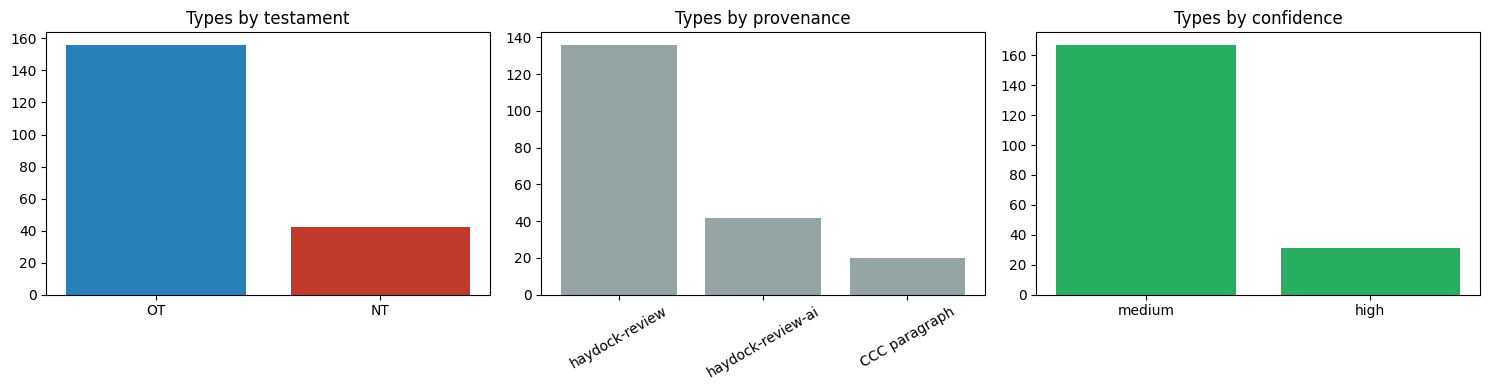

198 Types | OT=156, NT=42


In [4]:
with conn.session() as session:
    type_rows = session.run('''
        MATCH (t:Type)
        RETURN t.id AS id, t.name AS name, t.testament AS testament,
               t.source AS source, t.confidence AS confidence
    ''').data()

types_df = pd.DataFrame(type_rows)
# Collapse the many per-paragraph CCC provenances into one bucket
types_df["provenance"] = types_df["source"].where(
    ~types_df["source"].fillna("").str.startswith("CCC"), "CCC paragraph")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
testament_counts = types_df["testament"].value_counts()
axes[0].bar(testament_counts.index, testament_counts.values,
            color=[TESTAMENT_COLORS.get(t, OTHER_COLOR) for t in testament_counts.index])
axes[0].set_title("Types by testament")

prov = types_df["provenance"].value_counts()
axes[1].bar(prov.index, prov.values, color=OTHER_COLOR)
axes[1].set_title("Types by provenance")
axes[1].tick_params(axis="x", rotation=30)

conf = types_df["confidence"].value_counts()
axes[2].bar(conf.index, conf.values, color="#27ae60")
axes[2].set_title("Types by confidence")
plt.tight_layout()
plt.show()

print(f"{len(types_df)} Types | OT={testament_counts.get('OT', 0)}, "
      f"NT={testament_counts.get('NT', 0)}")

## 3. `PREFIGURES` — the type → antitype network

The core typological claims. Each edge says an OT type prefigures an NT antitype,
tagged with a theological **category** and backed by `sources` (e.g. CCC, Haydock)
and `source_verses`.

In [5]:
with conn.session() as session:
    pf_rows = session.run('''
        MATCH (a:Type)-[r:PREFIGURES]->(b:Type)
        RETURN a.id AS type_id, a.name AS type, b.id AS antitype_id,
               b.name AS antitype, a.testament AS from_t, b.testament AS to_t,
               r.category AS category, r.confidence AS confidence,
               size(r.sources) AS n_sources, size(r.source_verses) AS n_verses
    ''').data()

prefigures = pd.DataFrame(pf_rows)
print(f"{len(prefigures)} PREFIGURES edges")
print("\nDirection (testament -> testament):")
print((prefigures["from_t"] + " -> " + prefigures["to_t"]).value_counts().to_string())

272 PREFIGURES edges

Direction (testament -> testament):
OT -> NT    270
NT -> NT      1
OT -> OT      1


Category distribution — which kinds of typology dominate the graph.

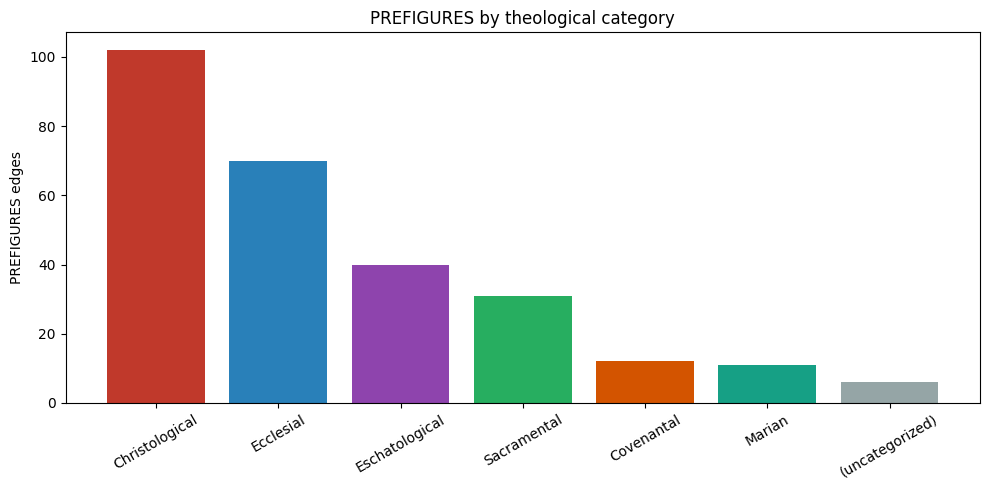

In [6]:
cat_counts = prefigures["category"].fillna("(uncategorized)").value_counts()
fig, ax = plt.subplots()
ax.bar(cat_counts.index, cat_counts.values,
       color=[cat_color(c) for c in cat_counts.index])
ax.set_ylabel("PREFIGURES edges")
ax.set_title("PREFIGURES by theological category")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Best-attested typological claims, ranked by number of supporting `source_verses`.

In [7]:
prefigures.sort_values(["n_verses", "n_sources"], ascending=False).head(TOP_N)[
    ["type", "antitype", "category", "confidence", "n_sources", "n_verses"]
].reset_index(drop=True)

,type,antitype,category,confidence,n_sources,n_verses
0,David,Christ,Christological,high,1,26
1,The Temple of Jerusalem,The One True Church,Ecclesial,high,1,11
2,Old Testament Priesthood,Christ the High Priest,Christological,high,2,10
3,Moses,Christ,Christological,high,1,9
4,Solomon,Christ,Christological,high,1,9
5,David,Christ's Passion,Christological,high,1,9
6,Cyrus,Christ,Christological,medium,1,8
7,Passover,Christ's Passion,Christological,high,1,8
8,The Mosaic Law,The Gospel (New Covenant),Covenantal,high,1,8
9,Joshua,Christ,Christological,high,1,7


**Antitype hubs** — the NT realities that the most OT types point toward.

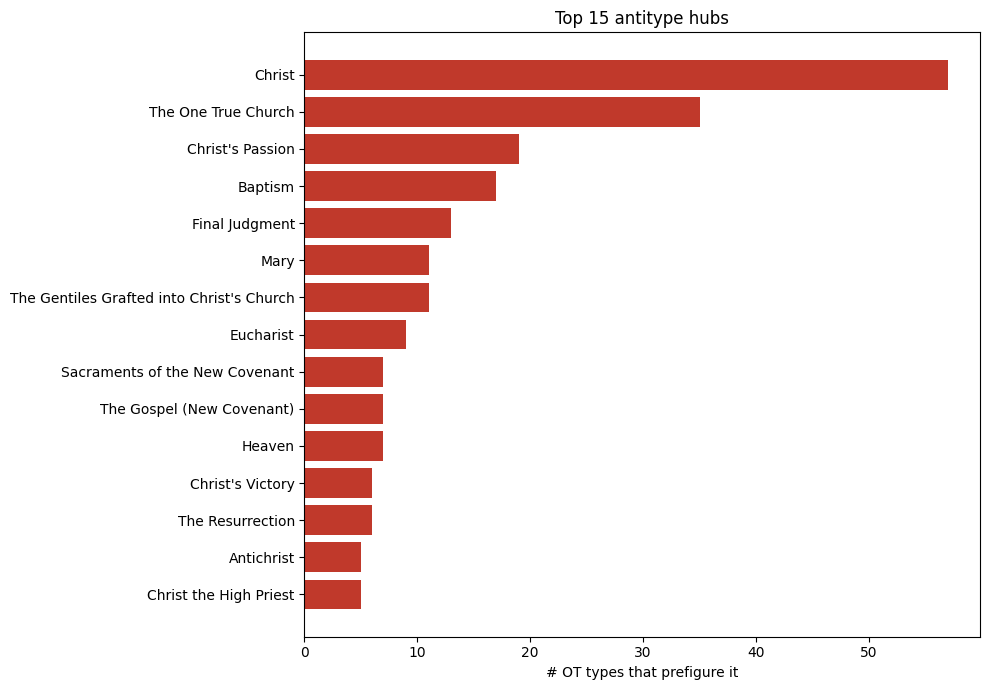

In [8]:
hubs = (prefigures.groupby(["antitype_id", "antitype"]).size()
        .reset_index(name="prefigured_by")
        .sort_values("prefigured_by", ascending=False).head(TOP_N).iloc[::-1])
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(hubs["antitype"], hubs["prefigured_by"], color=TESTAMENT_COLORS["NT"])
ax.set_xlabel("# OT types that prefigure it")
ax.set_title(f"Top {TOP_N} antitype hubs")
plt.tight_layout()
plt.show()

Interactive **PREFIGURES network** — every Type, edges colored by category,
node size scaled by how often a type is prefigured (its antitype in-degree).

In [9]:
with conn.session() as session:
    nodes = session.run('''
        MATCH (t:Type)
        OPTIONAL MATCH (:Type)-[r:PREFIGURES]->(t)
        RETURN t.id AS id, t.name AS name, t.testament AS testament,
               count(r) AS in_degree
    ''').data()
    edges = session.run('''
        MATCH (a:Type)-[r:PREFIGURES]->(b:Type)
        RETURN a.id AS src, b.id AS dst, r.category AS category
    ''').data()

net = Network(height="650px", width="100%", bgcolor="#ffffff", notebook=True,
              cdn_resources="in_line")
net.barnes_hut()
for n in nodes:
    net.add_node(n["id"], label=n["name"],
                 color=TESTAMENT_COLORS.get(n["testament"], OTHER_COLOR),
                 size=10 + 3 * n["in_degree"],
                 title=f"{n['name']} ({n['testament']}, prefigured by {n['in_degree']})")
for e in edges:
    net.add_edge(e["src"], e["dst"], color=cat_color(e["category"]),
                 title=e["category"] or "uncategorized")
net.write_html("typology_prefigures_network.html")
print("Wrote typology_prefigures_network.html "
      "(blue=OT, red=NT; edge color = category).")
from IPython.display import IFrame
IFrame("typology_prefigures_network.html", width="100%", height=670)

Received notification from DBMS server: <GqlStatusObject gql_status='01G11', status_description='warn: null value eliminated in set function', position=None, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_status_parameters': {}, '_severity': 'WARNING', 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\n        MATCH (t:Type)\n        OPTIONAL MATCH (:Type)-[r:PREFIGURES]->(t)\n        RETURN t.id AS id, t.name AS name, t.testament AS testament,\n               count(r) AS in_degree\n    '


Wrote typology_prefigures_network.html (blue=OT, red=NT; edge color = category).


## 4. `MEMBER_OF` — scriptural attestation (seed vs mined)

How many verses witness each type. The 2026-06-14 crossref-mining roughly
**doubled** this layer (555 curated → 1,130 total) by adding adjudicated,
human-reviewed memberships with `confidence` and `corroboration`.

In [10]:
with conn.session() as session:
    layer = session.run('''
        MATCH ()-[r:MEMBER_OF]->()
        RETURN sum(CASE WHEN r.source IS NULL THEN 1 ELSE 0 END) AS seed,
               sum(CASE WHEN r.source='crossref-mined' THEN 1 ELSE 0 END) AS mined
    ''').single()
    per_type = session.run('''
        MATCH (v:Verse)-[r:MEMBER_OF]->(t:Type)
        RETURN t.name AS type, t.testament AS testament,
               sum(CASE WHEN r.source IS NULL THEN 1 ELSE 0 END) AS seed,
               sum(CASE WHEN r.source='crossref-mined' THEN 1 ELSE 0 END) AS mined
    ''').data()

print(f"MEMBER_OF: seed={layer['seed']}, mined={layer['mined']}, "
      f"total={layer['seed'] + layer['mined']} "
      f"(+{layer['mined'] / layer['seed']:.0%} over seed)")

member_df = pd.DataFrame(per_type)
member_df["total"] = member_df["seed"] + member_df["mined"]
member_df.sort_values("total", ascending=False).head(TOP_N).reset_index(drop=True)

MEMBER_OF: seed=555, mined=575, total=1130 (+104% over seed)


,type,testament,seed,mined,total
0,David,OT,44,17,61
1,Old Testament Priesthood,OT,19,33,52
2,Old Testament Sacrifices,OT,19,30,49
3,Passover,OT,19,25,44
4,Dietary Laws,OT,2,35,37
5,Return from Babylonian Captivity,OT,18,17,35
6,Joseph,OT,5,29,34
7,Circumcision,OT,10,23,33
8,Eternal Life,NT,6,26,32
9,The Mosaic Law,OT,11,21,32


Quality of the mined edges: confidence split and corroboration spread.

Mined confidence:
confidence
high      438
medium    137


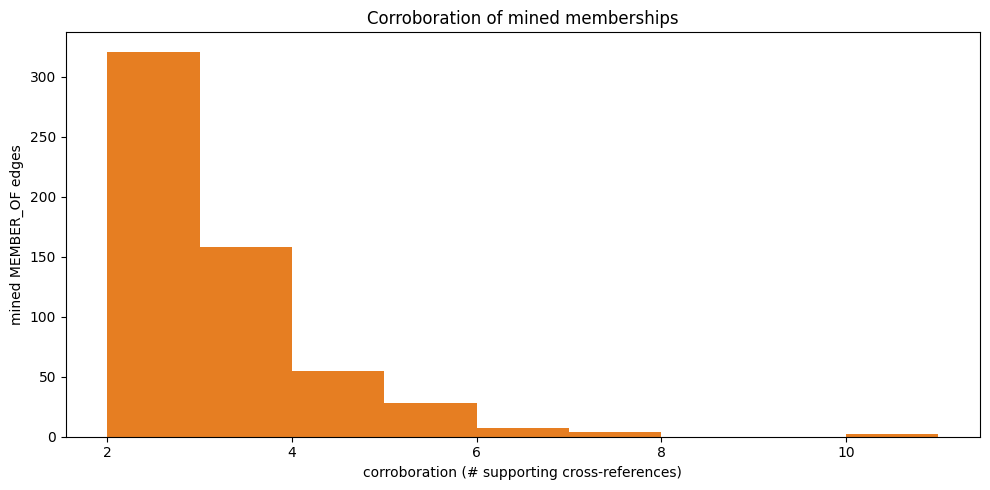

In [11]:
with conn.session() as session:
    mined_q = pd.DataFrame(session.run('''
        MATCH ()-[r:MEMBER_OF]->()
        WHERE r.source='crossref-mined'
        RETURN r.confidence AS confidence, r.corroboration AS corroboration
    ''').data())

print("Mined confidence:")
print(mined_q["confidence"].value_counts().to_string())

fig, ax = plt.subplots()
bins = range(int(mined_q["corroboration"].min()),
             int(mined_q["corroboration"].max()) + 2)
ax.hist(mined_q["corroboration"], bins=bins, color=MINED_COLOR)
ax.set_xlabel("corroboration (# supporting cross-references)")
ax.set_ylabel("mined MEMBER_OF edges")
ax.set_title("Corroboration of mined memberships")
plt.tight_layout()
plt.show()

## 5. `TEACHES` — Catechism → Type

CCC paragraphs that explicitly ground a type in magisterial teaching. This is the
thinnest layer (33 edges) and a candidate for future enrichment.

In [12]:
with conn.session() as session:
    teaches = pd.DataFrame(session.run('''
        MATCH (c:CatechismParagraph)-[:TEACHES]->(t:Type)
        RETURN c.id AS ccc, t.name AS type, t.testament AS testament
    ''').data())

print(f"{teaches['ccc'].nunique()} CCC paragraphs teach "
      f"{teaches['type'].nunique()} distinct Types ({len(teaches)} edges).")

# CCC paragraphs that teach the most types
by_ccc = (teaches.groupby("ccc").size().reset_index(name="types_taught")
          .sort_values("types_taught", ascending=False))
print("\nCCC paragraphs teaching the most types:")
print(by_ccc.head(TOP_N).to_string(index=False))

11 CCC paragraphs teach 20 distinct Types (33 edges).

CCC paragraphs teaching the most types:
     ccc  types_taught
CCC-1094             9
CCC-1150             4
CCC-1334             4
 CCC-117             3
CCC-1222             3
CCC-1544             3
CCC-1221             2
 CCC-527             2
 CCC-128             1
 CCC-129             1
 CCC-130             1


Which Types receive Catechism teaching.

In [13]:
(teaches.groupby(["type", "testament"]).size()
 .reset_index(name="ccc_paragraphs")
 .sort_values("ccc_paragraphs", ascending=False)
 .reset_index(drop=True))

,type,testament,ccc_paragraphs
0,Baptism,NT,5
1,Crossing of the Red Sea,OT,3
2,Christ,NT,3
3,Passover,OT,2
4,Melchizedek,OT,2
5,Eucharist,NT,2
6,Manna in the Desert,OT,2
7,Circumcision,OT,2
8,Crossing of the Jordan,OT,1
9,Eternal Life,NT,1


## 6. Integrated deep dive — *Christ* across all layers

The spotlight type pulls every edge family together: the verses that witness it
(`MEMBER_OF`), the OT figures that prefigure it (`PREFIGURES`), and the Catechism
paragraphs that teach it (`TEACHES`).

In [14]:
with conn.session() as session:
    summary = session.run('''
        MATCH (t:Type {id: $id})
        OPTIONAL MATCH (:Verse)-[m:MEMBER_OF]->(t)
        OPTIONAL MATCH (src:Type)-[:PREFIGURES]->(t)
        OPTIONAL MATCH (c:CatechismParagraph)-[:TEACHES]->(t)
        RETURN t.name AS name, t.testament AS testament,
               count(DISTINCT m) AS members,
               count(DISTINCT src) AS prefigured_by,
               count(DISTINCT c) AS taught_by
    ''', id=SPOTLIGHT_TYPE).single()
    top_prefig = pd.DataFrame(session.run('''
        MATCH (src:Type)-[r:PREFIGURES]->(t:Type {id: $id})
        RETURN src.name AS prefiguring_type, r.category AS category,
               size(r.source_verses) AS n_verses
        ORDER BY n_verses DESC, prefiguring_type LIMIT $n
    ''', id=SPOTLIGHT_TYPE, n=TOP_N).data())

print(f"{summary['name']} ({summary['testament']}): "
      f"{summary['members']} member verses, "
      f"prefigured by {summary['prefigured_by']} OT types, "
      f"taught by {summary['taught_by']} CCC paragraphs.")
print(f"\nTop OT types that prefigure {summary['name']}:")
top_prefig

Christ (NT): 27 member verses, prefigured by 57 OT types, taught by 3 CCC paragraphs.

Top OT types that prefigure Christ:


,prefiguring_type,category,n_verses
0,David,Christological,26
1,Moses,Christological,9
2,Solomon,Christological,9
3,Cyrus,Christological,8
4,Joshua,Christological,7
5,Return from Babylonian Captivity,Christological,7
6,Zorobabel,Christological,6
7,Joseph,Christological,5
8,The Exodus from Egypt,Christological,4
9,Adam,Christological,3


Ego network around the spotlight type: OT types that prefigure it (blue),
its member verses (orange/blue by layer), and CCC paragraphs that teach it
(purple). Edges are colored by family.

In [15]:
with conn.session() as session:
    ego_prefig = session.run('''
        MATCH (src:Type)-[r:PREFIGURES]->(t:Type {id: $id})
        RETURN src.id AS id, src.name AS name, r.category AS category
    ''', id=SPOTLIGHT_TYPE).data()
    ego_members = session.run('''
        MATCH (v:Verse)-[r:MEMBER_OF]->(t:Type {id: $id})
        RETURN v.id AS id,
               CASE WHEN r.source IS NULL THEN 'seed' ELSE 'mined' END AS layer
        ORDER BY r.corroboration DESC LIMIT 25
    ''', id=SPOTLIGHT_TYPE).data()
    ego_teaches = session.run('''
        MATCH (c:CatechismParagraph)-[:TEACHES]->(t:Type {id: $id})
        RETURN c.id AS id
    ''', id=SPOTLIGHT_TYPE).data()

net = Network(height="650px", width="100%", bgcolor="#ffffff", notebook=True,
              cdn_resources="in_line")
net.add_node(SPOTLIGHT_TYPE, label=summary["name"], color="#000000",
             size=34, shape="star")
for p in ego_prefig:
    net.add_node(p["id"], label=p["name"], color=TESTAMENT_COLORS["OT"], size=14)
    net.add_edge(p["id"], SPOTLIGHT_TYPE, color=cat_color(p["category"]),
                 title=f"PREFIGURES ({p['category']})")
for m in ego_members:
    net.add_node(m["id"], label=m["id"],
                 color=SEED_COLOR if m["layer"] == "seed" else MINED_COLOR, size=9)
    net.add_edge(m["id"], SPOTLIGHT_TYPE, color="#dddddd", title="MEMBER_OF")
for c in ego_teaches:
    net.add_node(c["id"], label=c["id"], color=CCC_COLOR, size=16, shape="square")
    net.add_edge(c["id"], SPOTLIGHT_TYPE, color=CCC_COLOR, title="TEACHES")

net.write_html(f"typology_{SPOTLIGHT_TYPE}_ego.html")
print(f"Wrote typology_{SPOTLIGHT_TYPE}_ego.html "
      f"(black star={summary['name']}; blue=OT types; "
      f"orange/blue=member verses; purple=CCC).")
from IPython.display import IFrame
IFrame(f"typology_{SPOTLIGHT_TYPE}_ego.html", width="100%", height=670)

Wrote typology_christ_ego.html (black star=Christ; blue=OT types; orange/blue=member verses; purple=CCC).


## 7. Best-supported Types — evidence on all fronts

Types that carry all three kinds of evidence (member verses **and** a place in the
PREFIGURES network **and** Catechism teaching) are the most richly grounded in the
graph — good entry points for study or visualization.

In [16]:
with conn.session() as session:
    best = pd.DataFrame(session.run('''
        MATCH (t:Type)
        OPTIONAL MATCH (:Verse)-[m:MEMBER_OF]->(t)
        OPTIONAL MATCH (t)-[pf:PREFIGURES]-(:Type)
        OPTIONAL MATCH (:CatechismParagraph)-[te:TEACHES]->(t)
        WITH t, count(DISTINCT m) AS members,
             count(DISTINCT pf) AS prefigures, count(DISTINCT te) AS teaches
        WHERE members > 0 AND prefigures > 0 AND teaches > 0
        RETURN t.name AS type, t.testament AS testament,
               members, prefigures, teaches,
               members + prefigures + teaches AS total
        ORDER BY total DESC
    ''').data())

print(f"{len(best)} Types have evidence on all three fronts.")
best.head(TOP_N).reset_index(drop=True)

Received notification from DBMS server: <GqlStatusObject gql_status='01G11', status_description='warn: null value eliminated in set function', position=None, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_status_parameters': {}, '_severity': 'WARNING', 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\n        MATCH (t:Type)\n        OPTIONAL MATCH (:Verse)-[m:MEMBER_OF]->(t)\n        OPTIONAL MATCH (t)-[pf:PREFIGURES]-(:Type)\n        OPTIONAL MATCH (:CatechismParagraph)-[te:TEACHES]->(t)\n        WITH t, count(DISTINCT m) AS members,\n             count(DISTINCT pf) AS prefigures, count(DISTINCT te) AS teaches\n        WHERE members > 0 AND prefigures > 0 AND teaches > 0\n        RETURN t.name AS type, t.testament AS testament,\n               members, prefigures, te

20 Types have evidence on all three fronts.


,type,testament,members,prefigures,teaches,total
0,Christ,NT,27,57,3,87
1,Old Testament Priesthood,OT,52,4,1,57
2,Old Testament Sacrifices,OT,49,6,1,56
3,Baptism,NT,30,17,5,52
4,Passover,OT,44,3,2,49
5,Circumcision,OT,33,2,2,37
6,Eternal Life,NT,32,3,1,36
7,Eucharist,NT,22,9,2,33
8,Manna in the Desert,OT,26,2,2,30
9,Cloud in the Desert,OT,25,3,1,29


## Cleanup

Close the database connection.

In [17]:
conn.close()
print("Connection closed.")

Connection closed.
